# CIE 2 – Activity 2: Binary Classification using Logistic Regression
## Banknote Authentication

**Problem:** Predict whether a banknote is genuine or forged using four numerical image features.

**Dataset:** UCI Banknote Authentication  
**Target:** `class` — 0 = Genuine, 1 = Forged  
**Algorithm:** Logistic Regression



## 1. Import libraries

In [1]:
!pip -q install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset

In [2]:
# Download dataset from UCI
banknote = fetch_ucirepo(id=267)

# Get input features and target
X = banknote.data.features
y = banknote.data.targets["class"]

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
display(X.head())

Dataset loaded successfully!
Dataset shape: (1372, 4)


,variance,skewness,curtosis,entropy
0,3.62160,8.6661,-2.8073,-0.44699
1,4.54590,8.1674,-2.4586,-1.46210
2,3.86600,-2.6383,1.9242,0.10645
3,3.45660,9.5228,-4.0112,-3.59440
4,0.32924,-4.4552,4.5718,-0.98880


## 3. Understand the data

In [3]:
# Show column names and data types
print("Column information:")
X.info()

# Show basic statistics
print("\nStatistical summary:")
display(X.describe())

# Check missing values
print("\nMissing values:")
print(X.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", X.duplicated().sum())

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
dtypes: float64(4)
memory usage: 43.0 KB

Statistical summary:


,variance,skewness,curtosis,entropy
count,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657
std,2.842763,5.869047,4.310030,2.101013
min,-7.042100,-13.773100,-5.286100,-8.548200
25%,-1.773000,-1.708200,-1.574975,-2.413450
50%,0.496180,2.319650,0.616630,-0.586650
75%,2.821475,6.814625,3.179250,0.394810
max,6.824800,12.951600,17.927400,2.449500



Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
dtype: int64

Duplicate records: 24


In [4]:
# Remove duplicate records
data = X.copy()
data["class"] = y

data = data.drop_duplicates()

# Separate features and target again
X = data.drop("class", axis=1)
y = data["class"]

print("Shape after removing duplicates:", data.shape)

Shape after removing duplicates: (1348, 5)


## 4. Check class distribution

Class counts:
class
0    738
1    610
Name: count, dtype: int64


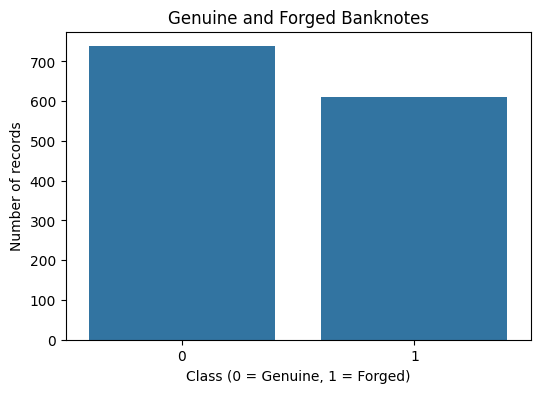

In [5]:
print("Class counts:")
print(y.value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title("Genuine and Forged Banknotes")
plt.xlabel("Class (0 = Genuine, 1 = Forged)")
plt.ylabel("Number of records")
plt.show()

## 5. Split the data

In [6]:
# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())

Training records: 1078
Testing records: 270

Training class counts:
class
0    590
1    488
Name: count, dtype: int64

Testing class counts:
class
0    148
1    122
Name: count, dtype: int64




## 6. Scale the features



In [7]:
scaler = StandardScaler()

# Learn scaling values from training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


## 7. Understand the sigmoid function

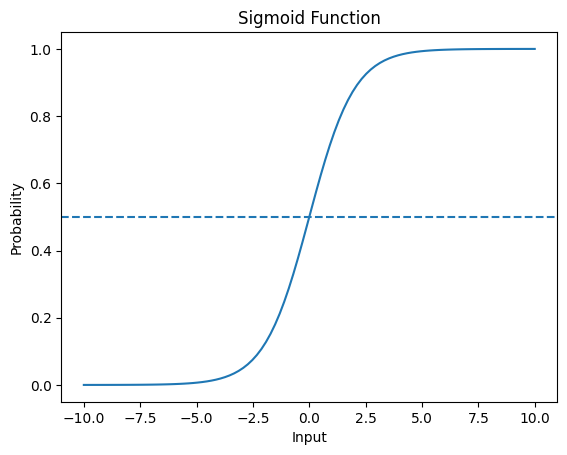

In [8]:
# Sigmoid converts a score into a value between 0 and 1
z = np.linspace(-10, 10, 100)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.axhline(0.5, linestyle="--")
plt.title("Sigmoid Function")
plt.xlabel("Input")
plt.ylabel("Probability")
plt.show()

## 8. Train the Logistic Regression model

In [9]:
model = LogisticRegression(max_iter=1000)

# Train model using training data
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained!")

Logistic Regression model trained!


## 9. Display coefficients and intercept

In [10]:
print("Intercept:", model.intercept_[0])

coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

display(coefficient_table)

Intercept: -1.0423299353287272


,Feature,Coefficient
0,variance,-4.634709
1,skewness,-4.738573
2,curtosis,-4.397133
3,entropy,0.235465


## 10. Predict probabilities and class labels

In [11]:
# Predict probability for each test record
probabilities = model.predict_proba(X_test_scaled)[:, 1]

# Convert probabilities into class labels using threshold 0.5
predictions = (probabilities >= 0.5).astype(int)

# Show actual and predicted values
result = pd.DataFrame({
    "Actual": y_test.values,
    "Forged Probability": probabilities,
    "Predicted": predictions
})

display(result.head(10).round(3))

,Actual,Forged Probability,Predicted
0,0,0.000,0
1,1,0.992,1
2,0,0.002,0
3,0,0.001,0
4,1,0.995,1
5,0,0.015,0
6,0,0.003,0
7,0,0.017,0
8,0,0.017,0
9,1,0.999,1


## 11. Confusion matrix

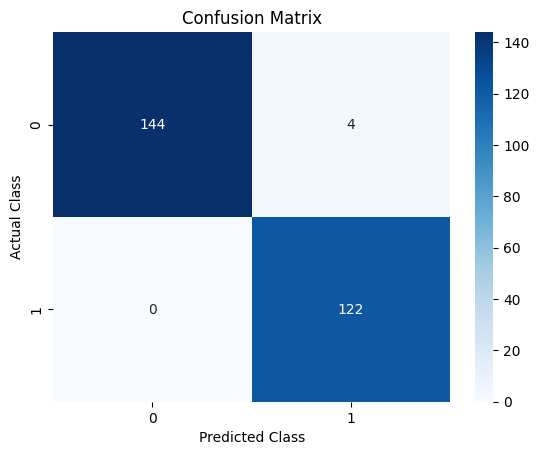

True Negative: 144
False Positive: 4
False Negative: 0
True Positive: 122


In [12]:
cm = confusion_matrix(y_test, predictions)

tn, fp, fn, tp = cm.ravel()

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

## 12. Calculate evaluation metrics

In [13]:
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, predictions)
auc = roc_auc_score(y_test, probabilities)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("Specificity:", round(specificity, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(auc, 4))

Accuracy: 0.9852
Precision: 0.9683
Recall: 1.0
Specificity: 0.973
F1 Score: 0.9839
ROC-AUC: 1.0


## 13. Classification report

In [14]:
print(classification_report(
    y_test, predictions,
    target_names=["Genuine", "Forged"]
))

              precision    recall  f1-score   support

     Genuine       1.00      0.97      0.99       148
      Forged       0.97      1.00      0.98       122

    accuracy                           0.99       270
   macro avg       0.98      0.99      0.99       270
weighted avg       0.99      0.99      0.99       270



## 14. Compare with a simple majority-class baseline

In [15]:
# Baseline always predicts the most common training class
majority_class = y_train.value_counts().idxmax()

baseline_predictions = np.full(len(y_test), majority_class)

print("Majority class:", majority_class)
print("Baseline accuracy:", accuracy_score(y_test, baseline_predictions))
print("Logistic Regression accuracy:", accuracy)

Majority class: 0
Baseline accuracy: 0.5481481481481482
Logistic Regression accuracy: 0.9851851851851852


## 15. Compare different thresholds

In [16]:
for threshold in [0.3, 0.5, 0.7]:
    new_predictions = (probabilities >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Predicted forged:", sum(new_predictions))
    print("Accuracy:", round(accuracy_score(y_test, new_predictions), 4))
    print("Precision:", round(precision_score(y_test, new_predictions), 4))
    print("Recall:", round(recall_score(y_test, new_predictions), 4))
    print("F1 Score:", round(f1_score(y_test, new_predictions), 4))


Threshold: 0.3
Predicted forged: 127
Accuracy: 0.9815
Precision: 0.9606
Recall: 1.0
F1 Score: 0.9799

Threshold: 0.5
Predicted forged: 126
Accuracy: 0.9852
Precision: 0.9683
Recall: 1.0
F1 Score: 0.9839

Threshold: 0.7
Predicted forged: 125
Accuracy: 0.9889
Precision: 0.976
Recall: 1.0
F1 Score: 0.9879


## 16. ROC curve

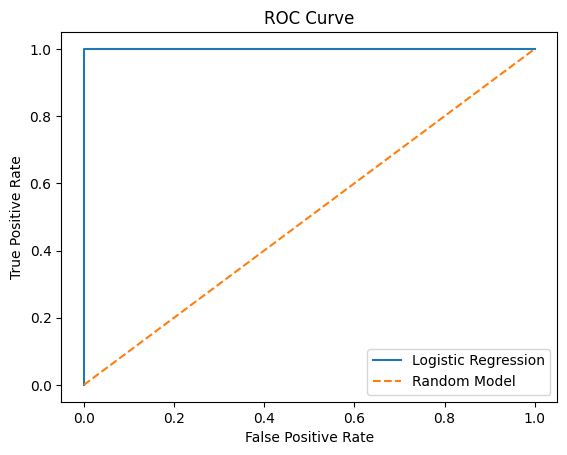

ROC-AUC Score: 1.0


In [17]:
fpr, tpr, thresholds = roc_curve(y_test, probabilities)

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Model")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

print("ROC-AUC Score:", round(auc, 4))

## 17. Compare training and testing accuracy

In [18]:
train_predictions = model.predict(X_train_scaled)
test_predictions = model.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))

Training Accuracy: 0.9944
Testing Accuracy: 0.9852


## 18. Decision behaviour graph

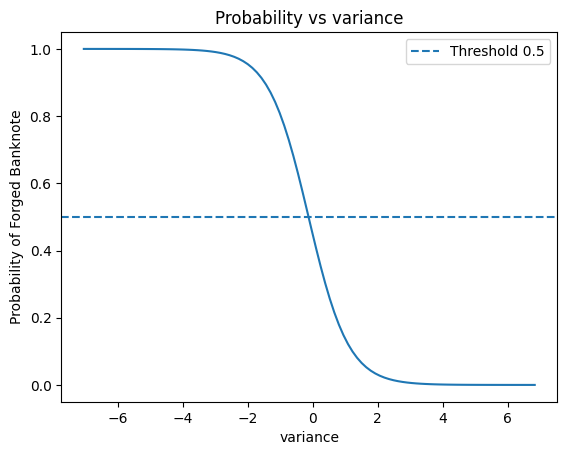

In [19]:
# Change one feature while keeping other features at their average
feature_name = X.columns[0]

feature_values = np.linspace(
    X[feature_name].min(), X[feature_name].max(), 100
)

new_data = pd.DataFrame(
    np.tile(X_train.mean().values, (100, 1)),
    columns=X.columns
)

new_data[feature_name] = feature_values

# Scale new data using the training scaler
new_data_scaled = scaler.transform(new_data)

new_probabilities = model.predict_proba(new_data_scaled)[:, 1]

plt.plot(feature_values, new_probabilities)
plt.axhline(0.5, linestyle="--", label="Threshold 0.5")
plt.title("Probability vs " + feature_name)
plt.xlabel(feature_name)
plt.ylabel("Probability of Forged Banknote")
plt.legend()
plt.show()

## 19. Predict one new example

In [20]:
# Take one record from the test set as an unseen example
new_banknote = X_test.iloc[[0]]

new_banknote_scaled = scaler.transform(new_banknote)

new_probability = model.predict_proba(new_banknote_scaled)[0][1]

if new_probability >= 0.5:
    print("Prediction: Forged Banknote")
else:
    print("Prediction: Genuine Banknote")

print("Probability of being forged:", round(new_probability, 4))

Prediction: Genuine Banknote
Probability of being forged: 0.0001


## Dataset source

UCI Machine Learning Repository – Banknote Authentication Dataset:

https://archive.ics.uci.edu/dataset/267/banknote+authentication

**Class labels:** 0 = Genuine, 1 = Forged.

